## Mathematical Model

\begin{align}
    \text{max} ~~ & x + y \\
    \text{s.t.}~~ & 6*x+4*y \le 24 \\
                  & x+2*y \le 6 \\
                  & y-x \le 1 \\
                  & y \le 2 \\
                  & x, y \ge 0
                  

\end{align}

In [1]:
# pip install gekko
from gekko import GEKKO
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Model
m = GEKKO()

# Vars
x,y = m.Array(m.Var, 2, lb=0)
y.UPPER = 2

# Constraints
m.Equations([6*x+4*y<=24, 
             x+2*y <=6, 
             y-x<=1])

# Obj Fct
m.Maximize(x+y)


In [3]:
# Solve
m.solve()
# m.solve(disp=False)

 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :            0
   Constants    :            0
   Variables    :            5
   Intermediates:            0
   Connections  :            0
   Equations    :            4
   Residuals    :            4
 
 Number of state variables:              5
 Number of total equations: -            3
 Number of slack variables: -            3
 ---------------------------------------
 Degrees of freedom       :             -1
 
 * Warning: DOF <= 0
 solver            3  not supported
 using default solver: APOPT
 ----------------------------------------------
 Steady State Optimization with APOPT Solver
 ----------------------------------------------
 
 Iter    Objective  Convergence
    0 -4.35897E+00  3.00000E+00
    1 -4.50000E+0

In [5]:
xopt = x.value[0]
yopt = y.value[0]
print(xopt, yopt)
print(-m.options.objfcnval) # '-' bc the solver change it to min fct when solves the optim pb

3.0 1.5
4.5


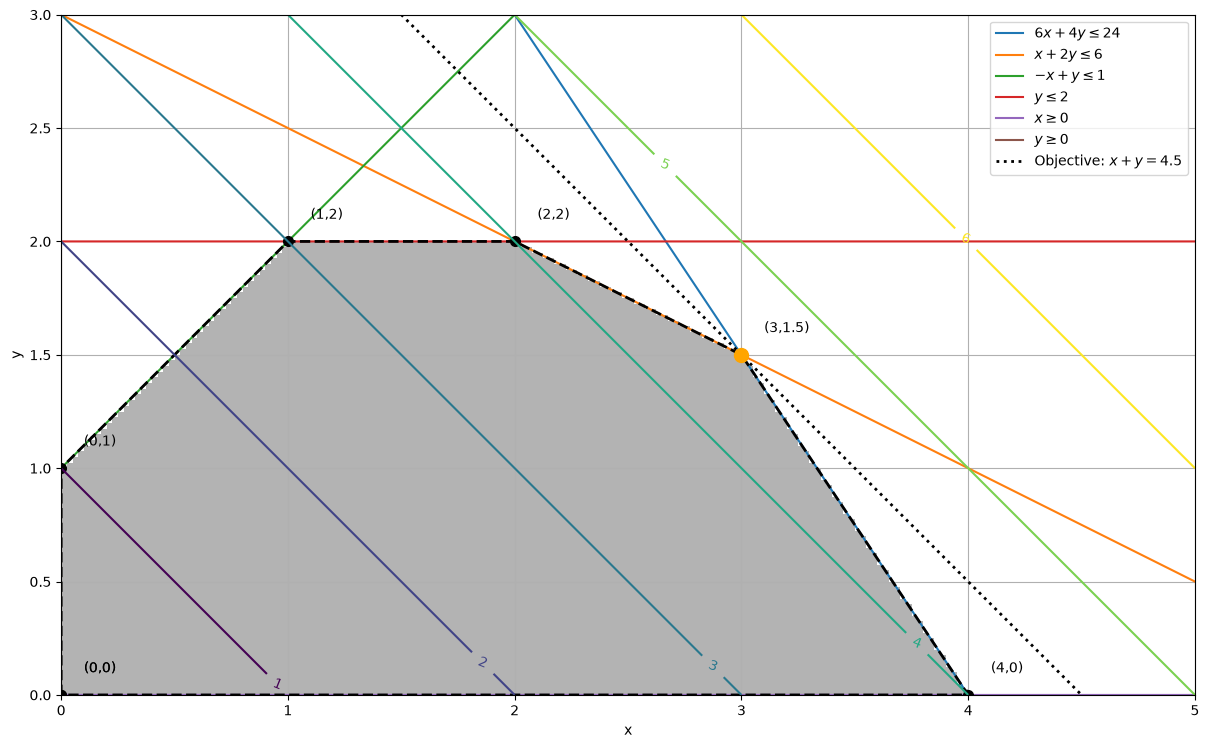

In [ ]:
# Visualize solution
plt.figure(figsize=(12, 8))
g = np.linspace(0,5,200)
x,y = np.meshgrid(g,g)
obj = x+y
plt.imshow(((6*x+4*y<=24)&(x+2*y<=6)&(-x+y<=1)&(y<=2)&(x>=0)&(y>=0)).astype(int),
    extent=(x.min(),x.max(),y.min(),y.max()),origin='lower',cmap='Greys',alpha=0.3);

# Constraints
x0 = np.linspace(0, 5, 2000)
y0 = 6-1.5*x0   # 6*x+4*y<=24
y1 = 3-0.5*x0   # x+2*y<=6
y2 = 1+x0       # -x+y<=1
y3 = (x0*0) + 2 # y <= 2
y4 = x0*0       # x >= 0

plt.plot(x0, y0, label=r'$6x+4y\leq24$')
plt.plot(x0, y1, label=r'$x+2y\leq6$')
plt.plot(x0, y2, label=r'$-x+y\leq1$')
plt.plot(x0, 2*np.ones_like(x0), label=r'$y\leq2$')
plt.plot(x0, y4, label=r'$x\geq0$')
plt.plot([0,0],[0,3], label=r'$y\geq0$')
xv = [0,0,1,2,3,4,0]; yv = [0,1,2,2,1.5,0,0]
plt.plot(xv,yv,'ko--',markersize=7,linewidth=2)
for i in range(len(xv)):
    plt.text(xv[i]+0.1,yv[i]+0.1,f'({xv[i]},{yv[i]})')


# Objective function at optimum: x + y = 4.5
x_obj = np.linspace(0, 4.5, 200)

CS = plt.contour(x,y,obj,np.arange(1,7))
plt.clabel(CS, inline=1, fontsize=10)

plt.plot(x_obj, 4.5 - x_obj, 'k:', linewidth=2,
         label=r'Objective: $x+y=4.5$')


plt.plot([xopt],[yopt],marker='o',color='orange',markersize=10)
plt.xlim(0,5); plt.ylim(0,3); plt.grid(); plt.tight_layout()
plt.legend(loc=1); plt.xlabel('x'); plt.ylabel('y')
plt.show()

### Resources
 - https://www.youtube.com/watch?v=a4CgoOqFimw
 - https://apmonitor.com/me575/index.php/Main/PythonOptimization